# MetricSuite 7 -- Curves: windows, clusters and difference curves

Many outputs are curves: a correlation over time, an error over SNR. Comparing two
methods "over time" can mean three different things, each with its own tool:

- **Part 1** -- registering and looking at curves;
- **Part 2** -- *is method A better on average over a window?* -> a window-mean test
  (one number per patient);
- **Part 3** -- *where in time does A differ from B?* -> a cluster permutation test,
  and how to correct it across several pairs;
- **Part 4** -- drawing it: group curves and difference curves with clusters;
- **Part 5** -- what a cluster result does and doesn't say.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="No clusters found")  # expected for a pair without any cluster

from mindmap.metric import MetricSuite

COLORS = {"wCSET": "#2a78d6", "CSET": "#1baf7a", "dSPM": "#e34948", "sLORETA": "#f0a020", "MNE": "#8c5bd6"}
COMPETITORS = ["CSET", "dSPM", "sLORETA", "MNE"]

## 📈 - Part 1: Registering curves

### The fake study

24 patients, five methods. For each, the spatial correlation between the true and
estimated sources over time around a spike (peak at 30 ms). `wCSET` gains around the
peak over `dSPM`, `sLORETA` and `MNE`; it is about as good as `CSET`. Each patient
has their own smooth baseline curve, shared by every method.

In [2]:
TIMES = np.round(np.linspace(-0.05, 0.15, 41), 3)
GAIN = {"wCSET": 0.12, "CSET": 0.10, "dSPM": 0.0, "sLORETA": 0.02, "MNE": -0.02}


def smooth_noise(rng, scale, width=4):
    x = rng.normal(0, 1, TIMES.size + 2 * width)
    kernel = np.hanning(2 * width + 1)
    y = np.convolve(x, kernel / kernel.sum(), mode="valid")
    return scale * y / y.std()


rng = np.random.default_rng(7)
suite = MetricSuite(name="Curves")
peak = np.exp(-((TIMES - 0.03) / 0.03) ** 2)
for p in range(24):
    patient_curve = 0.35 + 0.35 * peak + smooth_noise(rng, 0.08)
    for method, gain in GAIN.items():
        curve = patient_curve + gain * peak + smooth_noise(rng, 0.05)
        suite.register("correlation", curve, method=method, patient=f"P{p:02d}", times=TIMES)

suite.describe()

,Metric,Coord,Kind,N unique,Detail
0,correlation,method,categorical,5,"CSET, MNE, dSPM, sLORETA, wCSET"
1,correlation,patient,categorical,24,"P00, P01, P02, P03, P04, P05, P06, P07, ... (+..."
2,correlation,times,numerical,41,"[-0.05, 0.15]"


One `register` call per curve: `values` is the curve, `times=` labels each point.
`line` draws the mean curve per method with a 95% CI band across patients:

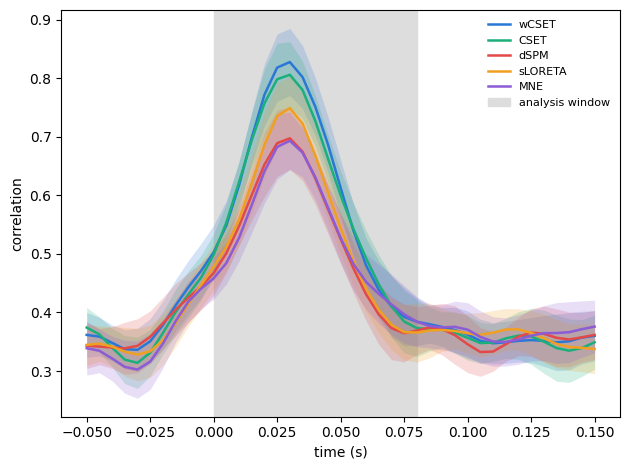

In [3]:
WINDOW = (0.0, 0.08)
fig, ax = suite.plot.line("correlation", x="times", hue="method", unit="patient",
                          hue_order=["wCSET"] + COMPETITORS, palette=COLORS, xlabel="time (s)")
ax.axvspan(*WINDOW, color="#dddddd", zorder=0, label="analysis window")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

## 🪟 - Part 2: The window-mean test

### One number per patient

The simplest question: averaged over a window chosen **in advance** (here 0-80 ms,
the spike's main deflection), is `wCSET` better? A paired test does this directly:
`filters` keeps the window's timepoints, and the test averages each patient's
curve over them before comparing -- one value per patient and method.

Filters match exact values, so take the window from the registered coordinate:

In [4]:
window_times = [t for t in TIMES if WINDOW[0] <= t <= WINDOW[1]]
in_window = {"times": window_times}

comparisons = suite.stat.build_comparisons("wCSET", COMPETITORS)
window = suite.stat.wilcoxon("correlation", "method", comparisons, pairing_col="patient",
                             filters=in_window, correction="holm",
                             effect_sizes=("rank_biserial", "hodges_lehmann"))
window.vs("wCSET")

,p_value,p_corrected,significant,rank_biserial,rank_biserial_ci_low,rank_biserial_ci_high,hodges_lehmann,hodges_lehmann_ci_low,hodges_lehmann_ci_high,offset,alternative,n_pairs,n_zero
method,,,,,,,,,,,,,
CSET,5.270591e-01,5.270591e-01,False,0.153333,-0.313333,0.573333,0.006053,-0.015022,0.028502,0.0,two-sided,24,0
dSPM,1.192093e-07,4.768372e-07,True,1.000000,1.000000,1.000000,0.075921,0.059426,0.094051,0.0,two-sided,24,0
sLORETA,1.192093e-06,2.384186e-06,True,0.966667,0.860000,1.000000,0.054918,0.037214,0.072959,0.0,two-sided,24,0
MNE,2.384186e-07,7.152557e-07,True,0.993333,0.960000,1.000000,0.074888,0.060670,0.091779,0.0,two-sided,24,0


The table already says how large, with intervals, from the very same window means
(`hodges_lehmann_ci_low`/`_ci_high`). For the figure on the right, `from_result`
turns the test into an `EstimateResult` for `plot.estimate`:

In [5]:
window_hl = suite.estimate.from_result(window)

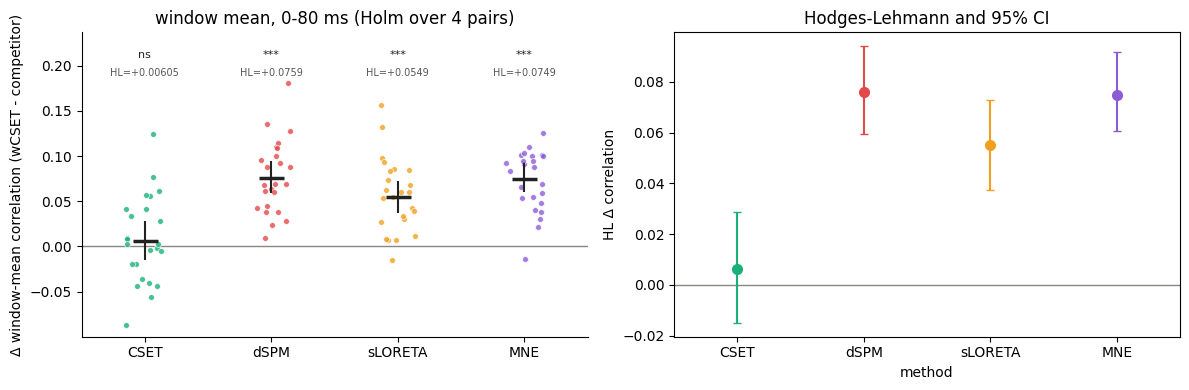

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
suite.plot.paired_differences(window, palette=COLORS, ax=axes[0], annotate=("stars", "hodges_lehmann"),
                              ylabel="Δ window-mean correlation (wCSET - competitor)",
                              title="window mean, 0-80 ms (Holm over 4 pairs)")
suite.plot.estimate(window_hl, reference="wCSET", palette=COLORS, ax=axes[1],
                    ylabel="HL Δ correlation", title="Hodges-Lehmann and 95% CI")
fig.tight_layout()

This is usually the **primary** analysis: one pre-specified number per patient,
an effect size with an interval, a family of 4 comparisons. It answers "better on
average over the window", not "when".

## 🧩 - Part 3: Cluster permutation -- where do they differ?

### The idea

Testing every timepoint separately would mean 41 tests, and neighbouring timepoints
aren't independent. A cluster permutation test (Maris & Oostenveld 2007):

1. computes a paired t statistic at every timepoint;
2. groups neighbouring timepoints above a threshold (`cluster_alpha`) into
   **clusters**, and sums their t values (the cluster *mass*);
3. repeats this many times with the sign of each patient's difference flipped at
   random, keeping the largest mass each time;
4. a cluster's p-value is the share of permutations whose largest mass beats it.

This controls the false-positive rate across all timepoints of **one** comparison.

### Restricted to the window

Pass the same `filters` to look only inside the pre-specified window:

In [7]:
clusters = suite.stat.cluster_permutation(
    "correlation", coord="times", group_by="method", comparisons=comparisons, pairing_col="patient",
    filters=in_window, n_permutations=5000, seed=0, correction="holm",
)
clusters

ClusterResult(metric='correlation', coord='times', n_pairs=4, correction='holm' (cluster family))
  wCSET vs CSET: no significant clusters
  wCSET vs dSPM: [0.0, 0.07] p=0.0006*, d=1.92
  wCSET vs sLORETA: [0.005, 0.07] p=0.0006*, d=1.38
  wCSET vs MNE: [0.0, 0.055] p=0.0006*, d=2.6

### Correcting across several pairs: the family

Each pair's permutation test controls errors *within* that pair. With 4 pairs, you
still need a correction *across* them. Two ways, set by `family`:

- `family="cluster"` (default): every cluster of every pair is one p-value in a
  single pooled family;
- `family="pair"`: **one p-value per pair** -- its smallest cluster p (1 if the
  pair has no cluster) -- corrected across the pairs. "Does wCSET differ from
  competitor X anywhere in the window?" with Holm across the 4 competitors. Each
  cluster's corrected p is then the larger of its pair's corrected p and its own p.

In [8]:
by_pair = suite.stat.cluster_permutation(
    "correlation", coord="times", group_by="method", comparisons=comparisons, pairing_col="patient",
    filters=in_window, n_permutations=5000, seed=0, correction="holm", family="pair",
)
by_pair.pair_table

,group_a,group_b,n_clusters,p_min,p_corrected,significant
0,wCSET,CSET,0,1.0000,1.0000,False
1,wCSET,dSPM,1,0.0002,0.0008,True
2,wCSET,sLORETA,1,0.0002,0.0008,True
3,wCSET,MNE,1,0.0002,0.0008,True


`pair_table` gives the per-pair verdict. A family can be changed after the fact
without rerunning the permutations:

In [9]:
pd.concat({"family='cluster'": clusters.pair_table.set_index("group_b")[["n_clusters", "p_min", "p_corrected"]],
           "family='pair'": by_pair.pair_table.set_index("group_b")[["n_clusters", "p_min", "p_corrected"]]}, axis=1)

family='cluster'                     family='pair'                    
              n_clusters   p_min p_corrected    n_clusters   p_min p_corrected
group_b                                                                       
CSET                   0  1.0000         NaN             0  1.0000      1.0000
dSPM                   1  0.0002      0.0006             1  0.0002      0.0008
sLORETA                1  0.0002      0.0006             1  0.0002      0.0008
MNE                    1  0.0002      0.0006             1  0.0002      0.0008

In [10]:
clusters.correct("holm", family="pair").pair_table.equals(by_pair.pair_table)

True

With `family="cluster"`, a pair without any cluster has no corrected p (NaN); with
`family="pair"` it gets p = 1 and still counts in the family. Here the verdicts
agree; they diverge when some pairs have several clusters or borderline ones.

Which to choose? `family="pair"` matches the usual claim ("wCSET differs from 3 of
4 competitors") and doesn't penalize a pair for having several clusters. Choose
before seeing the data, and report it.

## 📊 - Part 4: Drawing curves and clusters

### Group curves with significant clusters

`plot.cluster_permutation` draws each method's mean curve with its CI. A
competitor's points are solid inside one of its significant clusters and hollow
(dashed line) outside -- here `CSET` stays hollow, the three others are solid over
most of the window:

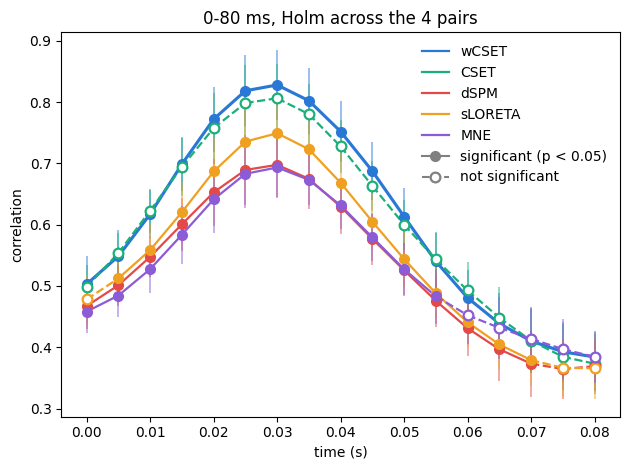

In [11]:
fig, ax = suite.plot.cluster_permutation(by_pair, palette=COLORS, xlabel="time (s)",
                                         ylabel="correlation", title="0-80 ms, Holm across the 4 pairs")
fig.tight_layout()

### Difference curves

`plot.paired_differences` on a cluster result draws, for each competitor, the
**difference curve** `wCSET - competitor` -- the mean across patients with a 95% CI
band -- and a bar along the bottom for each significant cluster. This is the figure
that shows *what* was tested: a difference, with its uncertainty at each timepoint.

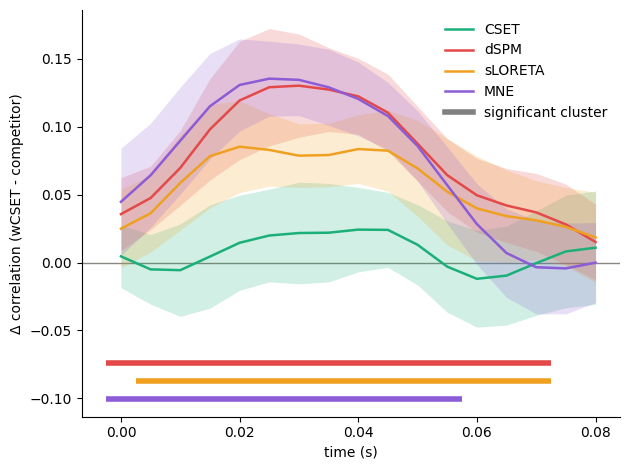

In [12]:
fig, ax = suite.plot.paired_differences(by_pair, palette=COLORS, xlabel="time (s)",
                                        ylabel="Δ correlation (wCSET - competitor)")
fig.tight_layout()

The per-patient differences behind it are available as a table:

In [13]:
suite.stat.paired_differences(by_pair).head()

,patient,times,method,Value
0,P00,0.000,CSET,-0.048253
1,P00,0.005,CSET,0.002709
2,P00,0.010,CSET,0.061590
3,P00,0.015,CSET,0.085871
4,P00,0.020,CSET,0.064103


## 🧭 - Part 5: What a cluster result says -- and doesn't

A significant cluster means: **the two conditions differ somewhere in the tested
range**, with the false-positive rate controlled. It does **not** establish:

- **when** the difference starts or ends -- cluster edges depend on the threshold
  and the noise; "the effect starts at 15 ms" isn't supported (Sassenhagen &
  Draschkow 2019);
- **how large** it is -- the cluster-mean effect size (`d` in the repr) is computed
  over timepoints *selected* for being large, so it's inflated.

Report instead:

- the window-mean test with its effect size and interval (Part 2) as the primary,
  quantitative result;
- the cluster test as "the difference is present within the window", with the
  difference curve and its CI band to show where it is large;
- the correction family you used, decided in advance.

### One more choice: the unit

As with every paired test, `pairing_col` must be the level where the effect
varies -- here the patient. If patients were simulated several times, average the
runs with `unit_col`; don't pair runs (tutorial 3, Part 1).

## Wrap-up

- Curves: one `register` per curve with a coordinate (`times=`); `plot.line` with
  `unit` to see them.
- **Window mean**: any paired test with `filters` on the window -- one value per
  patient; report HL / mean difference with intervals. Usually the primary result.
- **Cluster permutation**: `stat.cluster_permutation(..., filters=window)`;
  `family="pair"` + Holm for "differs from each competitor"; `pair_table` for the
  verdicts.
- **Plots**: `plot.cluster_permutation` (group curves), `plot.paired_differences`
  (difference curves with CI bands and cluster bars).
- Cluster results say *where something differs*, not exactly when, nor how much.

Next: **tutorial 8** -- a full revision plan, request by request.